# 4. Does the answer depend on the grid?

Counting cases in areas and then mapping the areas can change the answer when the
areas change: the **modifiable areal unit problem** (MAUP). Here every test is tied to
the location of its testing site, so the question becomes: *which sites end up in the
same cell?* A different grid groups sites differently.

To check this, the unchanged pipeline was run on **eight discrete global grid
systems** (DGGS) with cells of roughly the same size as H3 resolution 3: H3, S2, A5,
rHEALPix, HEALPix, DGGRID ISEA4H and ISEA3H, and OpenEAGGR ISEA4T. Exact sizes differ,
because each system steps between resolutions differently (from about 6 to 21
thousand km²). A signal that appears on most grids is robust; a signal that appears on
one grid only is more likely an artefact of where the cell borders fall.

In [1]:
# In the browser (JupyterLite) install the packages this notebook needs.
# On a normal Python kernel this cell does nothing.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["pandas", "geopandas", "shapely", "pyproj", "matplotlib", "scipy"])

In [2]:
import itertools
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hotspots_lite import build_info, load_oblasts, load_sites, load_cases, plot_labels, HOTSPOT_LABELS, DATA

info = build_info()
summary = pd.read_csv(DATA / "grids_summary.csv")
results = pd.read_csv(DATA / "grid_results.csv", dtype={"cell_id": str})
oblasts = load_oblasts()
summary

,grid,slug,resolution,n_cells,area_median_km2,area_min_km2,area_max_km2
0,H3,h3,res3,82,12031,11102,13079
1,S2,s2,L6,49,20866,18594,22898
2,A5,a5,res6,111,8302,8302,8302
3,rHEALPix,rhealpix,res4,79,12957,12957,12957
4,HEALPix (xdggs),healpix_xdggs,level6,96,10410,10399,10419
5,DGGRID ISEA4H,dggrid_isea4h,res6,76,12492,12479,12503
6,DGGRID ISEA3H,dggrid_isea3h,res8,113,7799,7791,7805
7,OpenEAGGR ISEA4T,openeaggr_isea4t,level6,146,6218,6210,6227


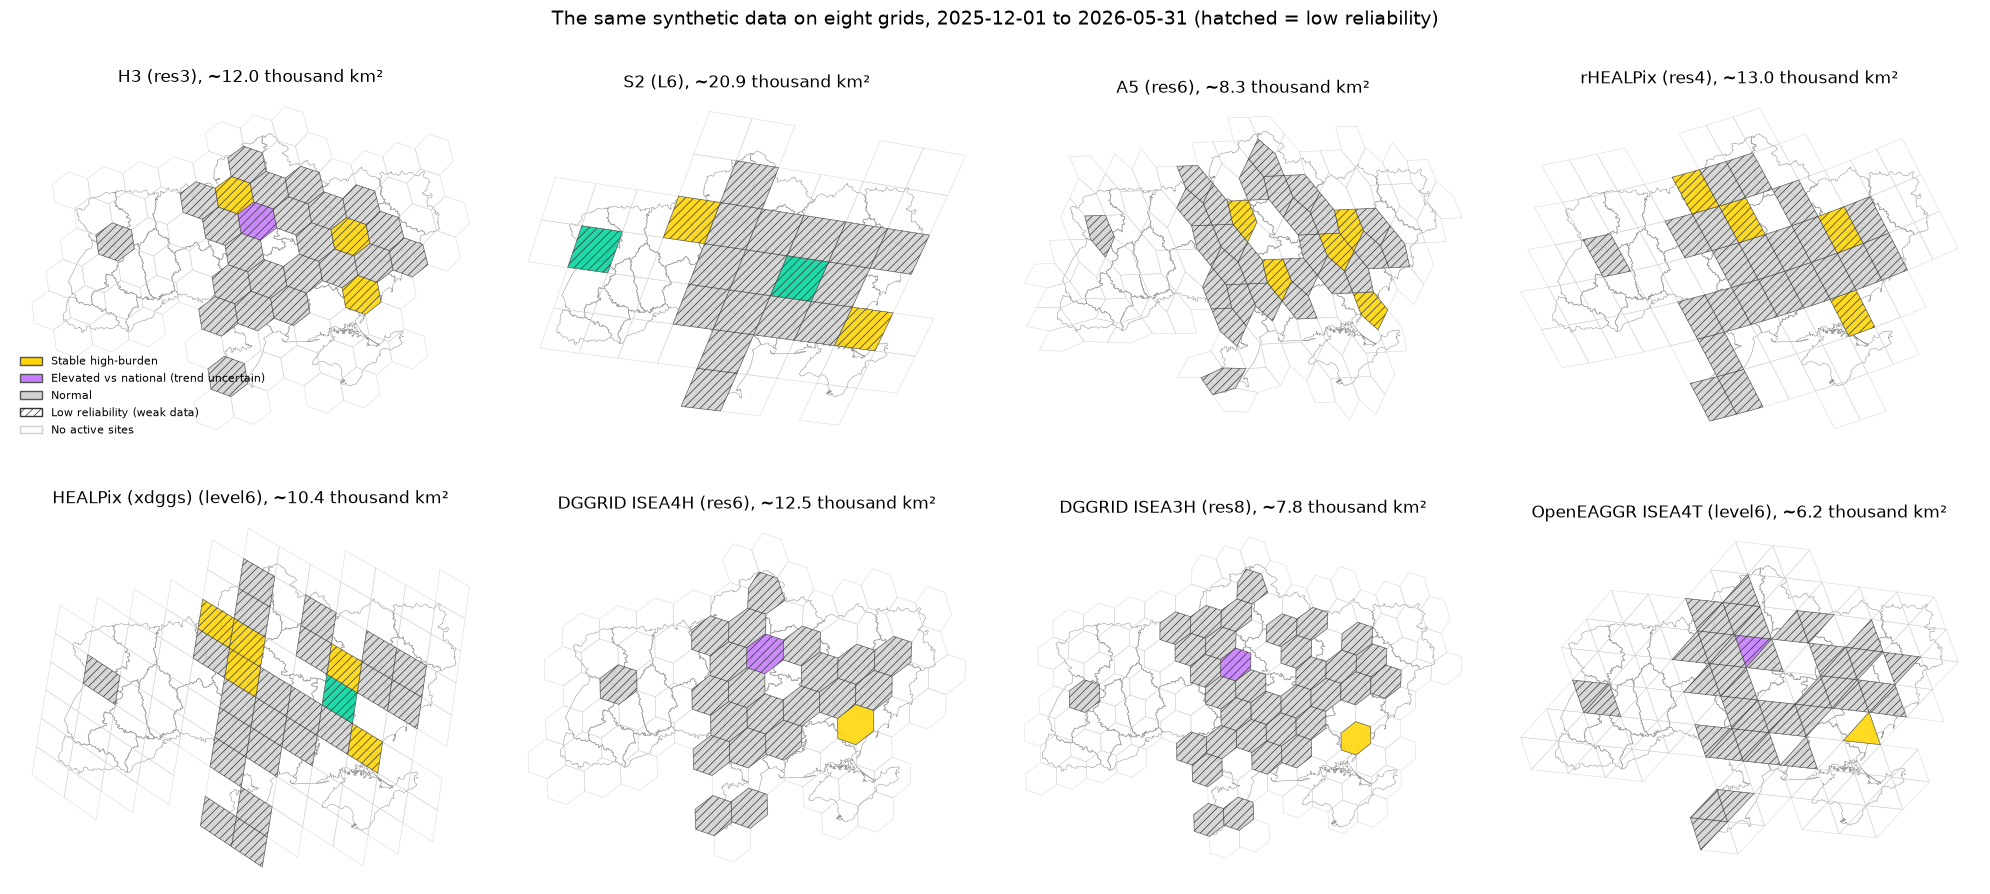

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
grids = {}
for ax, row in zip(axes.flat, summary.itertuples()):
    g = gpd.read_file(DATA / "grids" / f"{row.slug}.geojson")
    g["cell_id"] = g["cell_id"].astype(str)
    g = g.merge(results[results.grid == row.slug], on="cell_id", how="left")
    grids[row.slug] = g
    plot_labels(g, ax=ax, oblasts=oblasts, legend=(row.Index == 0),
                title=f"{row.grid} ({row.resolution}), ~{row.area_median_km2 / 1000:.1f} thousand km²")
plt.suptitle(f"The same synthetic data on eight grids, {info['window_start']} to {info['window_end']}"
             " (hatched = low reliability)", fontsize=14)
plt.tight_layout()
plt.show()

## Grid support for each site

Each site inherits the label of the cell it falls in, on every grid. A site's **grid
support** is the number of grids on which its cell is a hotspot. Only sites that tested
in the analysis window count.

In [4]:
cases = load_cases()
win = cases[(cases.test_date >= info["window_start"]) & (cases.test_date <= info["window_end"])]
act = win.groupby("site_id").agg(tests=("type", "size"), recent=("type", lambda x: (x == "recent").sum()))
sites = load_sites()
sites = sites[sites.site_id.isin(act.index)]

support = []
for slug, g in grids.items():
    j = gpd.sjoin(sites[["site_id", "geometry"]], g[["label", "geometry"]], how="left", predicate="within")
    support.append(j.assign(grid=slug, hot=j["label"].isin(HOTSPOT_LABELS))[["site_id", "grid", "hot"]])
support = pd.concat(support)
per_site = support.groupby("site_id")["hot"].sum().rename("grids_hot").to_frame().join(act)
per_site[per_site.grids_hot > 0].sort_values(["grids_hot", "recent"], ascending=False)

,grids_hot,tests,recent
site_id,,,
SITE_0037,8,93,4
SITE_0053,7,7,2
SITE_0056,4,29,3
SITE_0071,4,4,0
SITE_0021,3,32,3
SITE_0092,3,91,3
SITE_0044,3,5,1
SITE_0007,3,23,0
SITE_0060,3,8,0


## How similar are the grids?

The Jaccard index of the sets of sites that each pair of grids places in a hotspot
(1 = identical, 0 = no overlap).

In [5]:
sets = {s: set(support[(support.grid == s) & support.hot].site_id) for s in grids}
names = list(grids)
jac = pd.DataFrame(np.nan, index=names, columns=names)
for a, b in itertools.product(names, names):
    u = sets[a] | sets[b]
    jac.loc[a, b] = len(sets[a] & sets[b]) / len(u) if u else np.nan
jac.round(2)

,h3,s2,a5,rhealpix,healpix_xdggs,dggrid_isea4h,dggrid_isea3h,openeaggr_isea4t
h3,1.00,0.17,0.55,0.45,0.40,0.22,0.22,0.22
s2,0.17,1.00,0.08,0.33,0.21,0.17,0.17,0.17
a5,0.55,0.08,1.00,0.50,0.43,0.25,0.25,0.25
rhealpix,0.45,0.33,0.50,1.00,0.46,0.29,0.29,0.29
healpix_xdggs,0.40,0.21,0.43,0.46,1.00,0.17,0.17,0.17
dggrid_isea4h,0.22,0.17,0.25,0.29,0.17,1.00,1.00,1.00
dggrid_isea3h,0.22,0.17,0.25,0.29,0.17,1.00,1.00,1.00
openeaggr_isea4t,0.22,0.17,0.25,0.29,0.17,1.00,1.00,1.00


## How we use this

Applied to the real data, this check led to three conclusions that the synthetic
example also illustrates:

* the strongest signals appear on most grids, so the choice of grid does not create
  them;
* what the grid does change is **which neighbouring sites share a cell** with the
  site that produces the signal, and therefore the outline and the name of the hotspot
  on the map;
* H3 agreed with the majority of the other grids about as well as any other grid did.

H3 therefore stays the primary grid, the multi-grid comparison is run as a
sensitivity analysis, and a hotspot is reported together with the sites that produce
its recent results, not only with the name of the area at the cell's centre.